# Phân khúc khách hàng và đề xuất chiến lược dựa trên hành vi tiêu dùng
**TÊN ĐỀ TÀI: PHÂN KHÚC KHÁCH HÀNG VÀ ĐỀ XUẤT CHIẾN LƯỢC DỰA TRÊN HÀNH VI TIÊU DÙNG**

Notebook gồm: mô tả dữ liệu, tiền xử lý, trực quan hóa, chọn k bằng Elbow/Silhouette, K-Means và mô tả 5 cụm.


## 1. Khai báo thư viện và đọc dữ liệu
Tải lên tệp CSV đang sử dụng trong báo cáo. Notebook không tự tạo dữ liệu mới.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
uploaded = files.upload()

# Đọc tệp CSV vừa tải lên
csv_files = [name for name in uploaded.keys() if name.lower().endswith('.csv')]
if not csv_files:
    raise ValueError("Hãy tải lên tệp dữ liệu định dạng .csv")
file_name = csv_files[0]
df = pd.read_csv(file_name)

print("Tên file:", file_name)
print("Kích thước dữ liệu:", df.shape)
display(df.head())


Saving store_customers.csv to store_customers.csv
Tên file: store_customers.csv
Kích thước dữ liệu: (1000, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1000,M,39.0,59.9,58.0
1,1001,M,34.0,48.4,37.0
2,1002,F,40.0,70.5,26.0
3,1003,F,47.0,81.1,30.0
4,1004,F,33.0,42.1,58.0


**Thư viện được nạp và tệp CSV được đọc vào DataFrame. Nếu chương trình báo lỗi thiếu cột hoặc không tìm thấy tệp, cần kiểm tra lại tên tệp và tên các cột trong dữ liệu trước khi tiếp tục**

## 2. Mô tả dữ liệu

In [2]:
print("Thông tin dữ liệu:")
df.info()

print("\\nThống kê mô tả:")
display(df.describe(include='all'))

print("\\nTên các cột:")
print(df.columns.tolist())


Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   CustomerID              1000 non-null   int64  
 1   Gender                  997 non-null    object 
 2   Age                     994 non-null    float64
 3   Annual Income (k$)      996 non-null    float64
 4   Spending Score (1-100)  994 non-null    float64
dtypes: float64(3), int64(1), object(1)
memory usage: 39.2+ KB
\nThống kê mô tả:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
count,1000.000000,997,994.000000,996.000000,994.000000
unique,NaN,2,NaN,NaN,NaN
top,NaN,F,NaN,NaN,NaN
freq,NaN,522,NaN,NaN,NaN
mean,1499.500000,NaN,38.935614,57.149096,42.645875
std,288.819436,NaN,13.399880,28.628506,20.101589
min,1000.000000,NaN,18.000000,15.000000,1.000000
25%,1249.750000,NaN,30.000000,34.975000,31.000000
50%,1499.500000,NaN,36.000000,49.000000,47.000000
75%,1749.250000,NaN,44.000000,79.400000,57.000000


\nTên các cột:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


**Dựa vào df.info() và bảng thống kê mô tả, xác định số dòng, số cột, kiểu dữ liệu và phạm vi giá trị của từng biến. Đối chiếu với báo cáo: dữ liệu dự kiến có 1.000 khách hàng và 5 cột; nếu kết quả khác, cần xác nhận đúng phiên bản CSV đang dùng**

## 3. Tiền xử lý dữ liệu
Theo báo cáo: kiểm tra trùng lặp, loại `CustomerID`, mã hóa `Gender`, điền thiếu bằng Median/Mode và chuẩn hóa Z-score.

In [3]:
# Làm việc trên bản sao dữ liệu
data = df.copy()

# Chuẩn hóa tên cột để tránh lỗi do khoảng trắng đầu/cuối
data.columns = data.columns.str.strip()

# Kiểm tra trùng lặp
print("Số dòng trùng lặp:", data.duplicated().sum())
data = data.drop_duplicates().copy()

# Xác định tên cột tương ứng với các biến trong báo cáo
required = ['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']
missing_cols = [c for c in required if c not in data.columns]
if missing_cols:
    raise ValueError(
        f"Không tìm thấy các cột: {missing_cols}. "
        f"Các cột hiện có: {data.columns.tolist()}"
    )

# Kiểm tra giá trị khuyết thiếu trước khi xử lý
print("Giá trị thiếu trước xử lý:")
display(data.isnull().sum())

# Bỏ biến định danh CustomerID
data = data.drop(columns=['CustomerID'])

# Mã hóa Gender thành số; giữ nguyên mapping để có thể kiểm tra
gender_map = {'Female': 0, 'Male': 1, 'F': 0, 'M': 1}
data['Gender'] = data['Gender'].replace(gender_map)

# Điền thiếu: biến số dùng Median, Gender dùng Mode
numeric_cols = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
for col in numeric_cols:
    data[col] = pd.to_numeric(data[col], errors='coerce')
    data[col] = data[col].fillna(data[col].median())

mode_gender = data['Gender'].mode(dropna=True)
if not mode_gender.empty:
    data['Gender'] = data['Gender'].fillna(mode_gender.iloc[0])

# Đảm bảo Gender là dạng số sau mã hóa
data['Gender'] = pd.to_numeric(data['Gender'], errors='coerce')
if data['Gender'].isna().any():
    raise ValueError("Gender còn giá trị chưa mã hóa. Hãy kiểm tra giá trị gốc trong cột Gender.")

print("Giá trị thiếu sau xử lý:")
display(data.isnull().sum())
print("Kích thước sau tiền xử lý:", data.shape)
display(data.head())


Số dòng trùng lặp: 0
Giá trị thiếu trước xử lý:


,0
CustomerID,0
Gender,3
Age,6
Annual Income (k$),4
Spending Score (1-100),6


Giá trị thiếu sau xử lý:


/tmp/ipykernel_3416/1650072343.py:29: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data['Gender'] = data['Gender'].replace(gender_map)


,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


Kích thước sau tiền xử lý: (1000, 4)


,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1.0,39.0,59.9,58.0
1,1.0,34.0,48.4,37.0
2,0.0,40.0,70.5,26.0
3,0.0,47.0,81.1,30.0
4,0.0,33.0,42.1,58.0


**Sau tiền xử lý, dữ liệu được kiểm tra trùng lặp, bỏ mã định danh CustomerID, mã hóa giới tính và xử lý giá trị thiếu theo quy tắc trong báo cáo. Kiểm tra các thông báo và bảng kết quả vừa in để xác nhận số dòng còn lại và dữ liệu thiếu đã được xử lý; không nên coi mã khách hàng là đặc trưng phân cụm**

### 3.1. Chuẩn hóa Z-score
Chuẩn hóa các biến số theo nội dung báo cáo. Giữ riêng bảng dữ liệu chưa chuẩn hóa để biểu đồ vẫn thể hiện đơn vị gốc.

In [4]:
from sklearn.preprocessing import StandardScaler

scale_cols = ['Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']
scaler = StandardScaler()
scaled_data = data.copy()
scaled_data[scale_cols] = scaler.fit_transform(data[scale_cols])

print("Dữ liệu sau chuẩn hóa:")
display(scaled_data.head())
print("\\nTrung bình sau chuẩn hóa:")
display(scaled_data[scale_cols].mean().round(3))
print("\\nĐộ lệch chuẩn sau chuẩn hóa:")
display(scaled_data[scale_cols].std(ddof=0).round(3))


Dữ liệu sau chuẩn hóa:


,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1.051315,0.006140,0.097456,0.765102
1,1.051315,-0.368256,-0.305184,-0.283120
2,-0.951190,0.081019,0.468586,-0.832188
3,-0.951190,0.605175,0.839715,-0.632527
4,-0.951190,-0.443136,-0.525761,0.765102


\nTrung bình sau chuẩn hóa:


,0
Gender,0.0
Age,0.0
Annual Income (k$),-0.0
Spending Score (1-100),0.0


\nĐộ lệch chuẩn sau chuẩn hóa:


,0
Gender,1.0
Age,1.0
Annual Income (k$),1.0
Spending Score (1-100),1.0


**Z-score đưa các biến số về thang đo có trung bình gần 0 và độ lệch chuẩn gần 1, giúp hạn chế việc biến có đơn vị hoặc độ lớn lớn chi phối mô hình. Trong báo cáo, phần phân cụm chủ yếu diễn giải theo thu nhập và điểm chi tiêu; vì vậy notebook vẫn giữ dữ liệu gốc để diễn giải kết quả theo đơn vị ban đầu**

## 4. Trực quan hóa dữ liệu
Các biểu đồ dưới đây theo thứ tự báo cáo: biểu đồ tròn, boxplot, histogram, ma trận tương quan và scatter plot.

### 4.1. Biểu đồ tròn — phân bổ giới tính

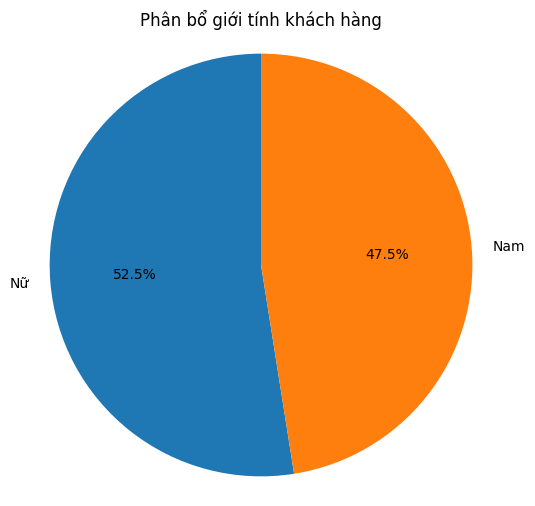

In [5]:
gender_counts = data['Gender'].map({0: 'Nữ', 1: 'Nam'}).fillna(data['Gender'].astype(str)).value_counts()
plt.figure(figsize=(6, 6))
plt.pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Phân bổ giới tính khách hàng')
plt.axis('equal')
plt.show()


**Biểu đồ tròn cho biết tỷ trọng khách hàng theo giới tính. So sánh tỷ lệ hiển thị với báo cáo (Nữ 52,4%, Nam 47,6%); nếu không trùng khớp, hãy kiểm tra cách mã hóa giới tính và phiên bản dữ liệu**

### 4.2. Biểu đồ hộp — thu nhập theo giới tính

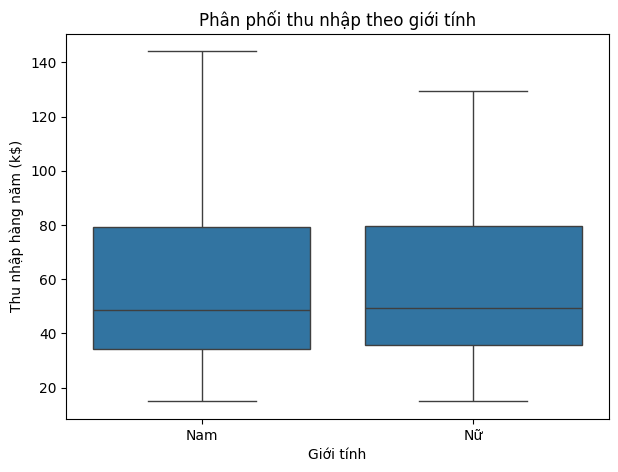

In [6]:
gender_labels = data['Gender'].map({0: 'Nữ', 1: 'Nam'}).fillna(data['Gender'].astype(str))
plt.figure(figsize=(7, 5))
sns.boxplot(x=gender_labels, y=data['Annual Income (k$)'])
plt.xlabel('Giới tính')
plt.ylabel('Thu nhập hàng năm (k$)')
plt.title('Phân phối thu nhập theo giới tính')
plt.show()


**Boxplot giúp so sánh trung vị, độ phân tán và các giá trị ngoại lệ của thu nhập giữa các nhóm giới tính. Dựa trên biểu đồ thực tế để nhận xét nhóm nào có trung vị thu nhập cao hơn; không kết luận khác biệt có ý nghĩa thống kê chỉ từ boxplot**

### 4.3. Histogram — tuổi, thu nhập và điểm chi tiêu

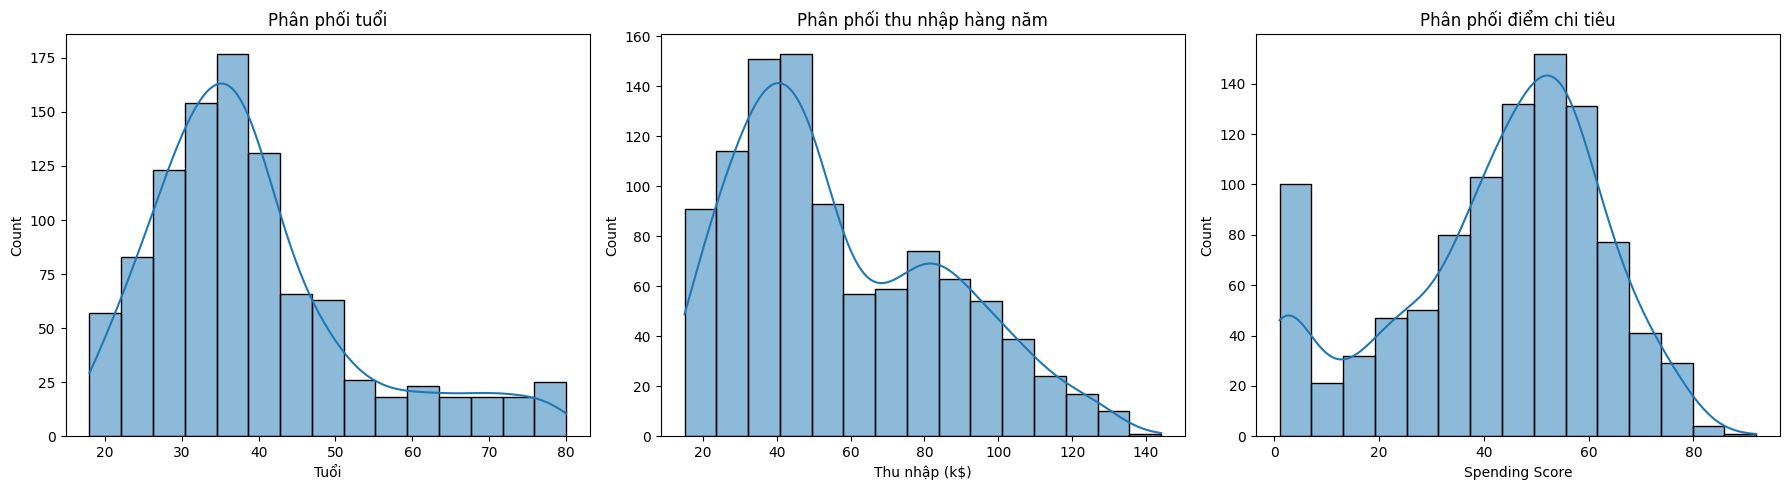

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(data['Age'], bins=15, kde=True, ax=axes[0])
axes[0].set_title('Phân phối tuổi')
axes[0].set_xlabel('Tuổi')

sns.histplot(data['Annual Income (k$)'], bins=15, kde=True, ax=axes[1])
axes[1].set_title('Phân phối thu nhập hàng năm')
axes[1].set_xlabel('Thu nhập (k$)')

sns.histplot(data['Spending Score (1-100)'], bins=15, kde=True, ax=axes[2])
axes[2].set_title('Phân phối điểm chi tiêu')
axes[2].set_xlabel('Spending Score')

plt.tight_layout()
plt.show()


**Ba histogram thể hiện phân phối độ tuổi, thu nhập hằng năm và điểm chi tiêu. Quan sát độ tập trung, độ lệch và các vùng giá trị phổ biến để mô tả đặc điểm khách hàng; đối chiếu hình dạng phân phối với biểu đồ trong báo cáo**

### 4.4. Ma trận tương quan

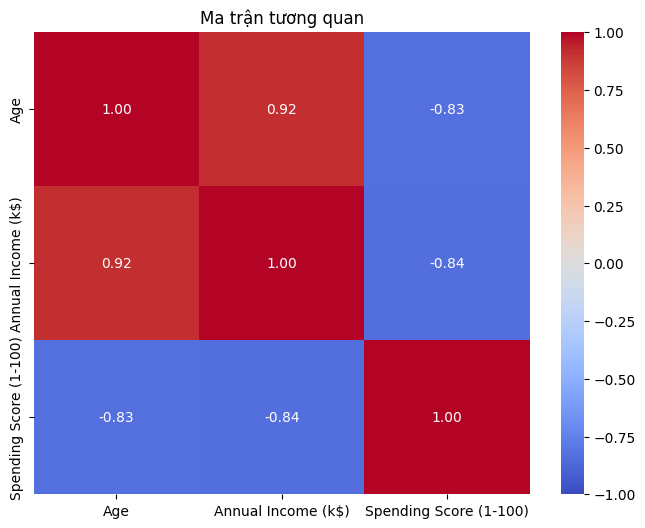

In [8]:
plt.figure(figsize=(8, 6))
corr = data[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Ma trận tương quan')
plt.show()


**Heatmap thể hiện chiều và mức độ tương quan tuyến tính giữa các biến. Báo cáo mô tả tương quan dương mạnh giữa tuổi và thu nhập, đồng thời tương quan âm giữa điểm chi tiêu với tuổi và thu nhập. Hãy dùng các hệ số được in trên heatmap để xác nhận; tương quan không đồng nghĩa với quan hệ nhân quả**

### 4.5. Biểu đồ phân tán

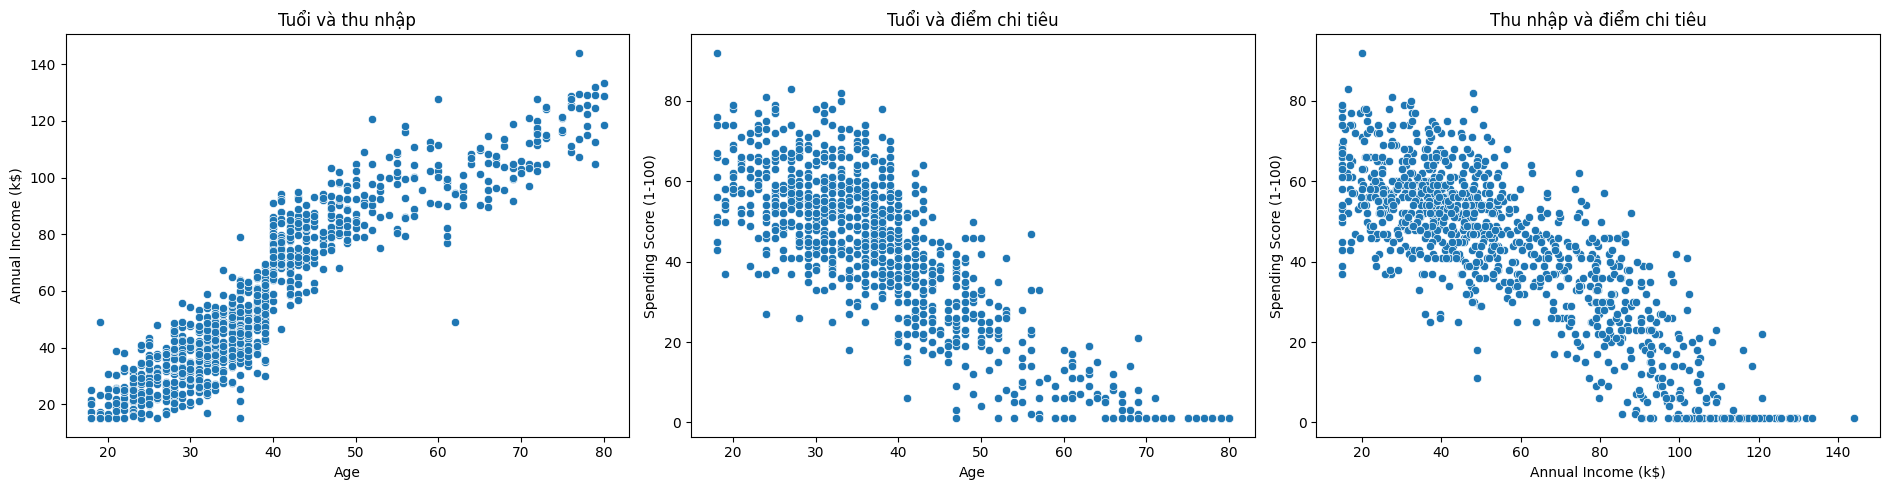

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

sns.scatterplot(data=data, x='Age', y='Annual Income (k$)', ax=axes[0])
axes[0].set_title('Tuổi và thu nhập')

sns.scatterplot(data=data, x='Age', y='Spending Score (1-100)', ax=axes[1])
axes[1].set_title('Tuổi và điểm chi tiêu')

sns.scatterplot(data=data, x='Annual Income (k$)', y='Spending Score (1-100)', ax=axes[2])
axes[2].set_title('Thu nhập và điểm chi tiêu')

plt.tight_layout()
plt.show()


**Các biểu đồ phân tán cho thấy mối liên hệ và mức độ phân tán giữa từng cặp biến. Dựa trên điểm dữ liệu thực tế để nhận xét xu hướng tăng/giảm và các nhóm quan sát; không suy ra quan hệ nhân quả từ biểu đồ**

## 5. Xây dựng mô hình K-Means
Trong báo cáo, chân dung các cụm được mô tả bằng **Annual Income (k$)** và **Spending Score (1-100)**. Vì vậy phần phân cụm dùng đúng hai biến này.

In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

features = ['Annual Income (k$)', 'Spending Score (1-100)']
X = data[features].copy()

# Chuẩn hóa hai biến dùng cho K-Means để khoảng cách không bị chi phối bởi thang đo
model_scaler = StandardScaler()
X_scaled = model_scaler.fit_transform(X)



**Các đặc trưng dùng cho K-Means ở phần này là thu nhập hằng năm và điểm chi tiêu, phù hợp với cách báo cáo mô tả chân dung cụm. Hai biến được chuẩn hóa trước khi phân cụm để đưa về cùng thang đo. Lưu ý báo cáo có chỗ nhắc thêm tuổi/giới tính trong tiền xử lý, nên cần trình bày rõ lựa chọn đặc trưng này khi thuyết trình**

### 5.1. Chọn số cụm bằng Elbow

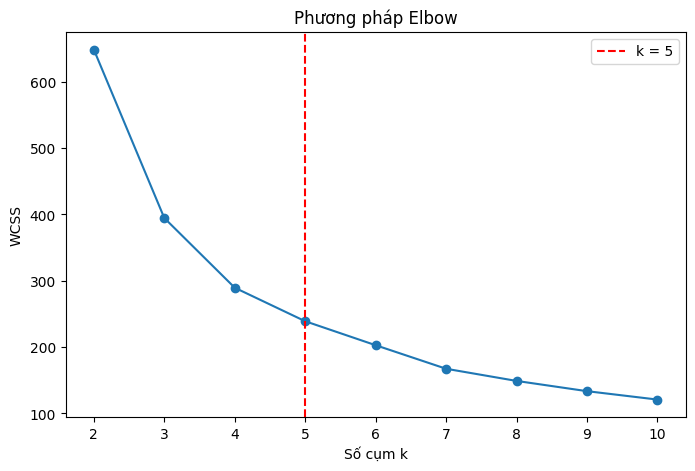

In [11]:
wcss = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), wcss, marker='o')
plt.axvline(x=5, color='red', linestyle='--', label='k = 5')
plt.xlabel('Số cụm k')
plt.ylabel('WCSS')
plt.title('Phương pháp Elbow')
plt.legend()
plt.show()


**Elbow hỗ trợ chọn số cụm bằng cách tìm điểm mà mức giảm WCSS bắt đầu chậm lại. Theo báo cáo, lựa chọn là k = 5. Hãy kiểm tra đường cong thực tế xem tại k = 5 có xuất hiện điểm gấp khúc tương đối rõ hay không; Elbow là tiêu chí hỗ trợ, không phải bằng chứng duy nhất**

### 5.2. Chọn số cụm bằng Silhouette

,k,Silhouette Score
0,2,0.580001
1,3,0.473520
2,4,0.392734
3,5,0.365806
4,6,0.349087
5,7,0.371942
6,8,0.358879
7,9,0.353146
8,10,0.347753


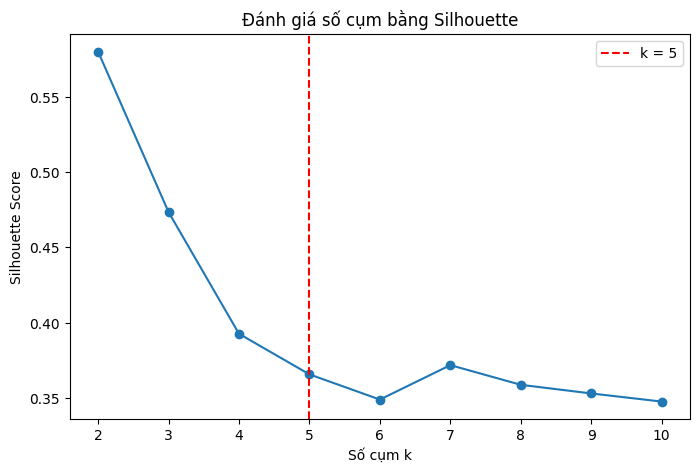

In [12]:
silhouette_scores = []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

silhouette_results = pd.DataFrame({
    'k': list(k_values),
    'Silhouette Score': silhouette_scores
})
display(silhouette_results)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), silhouette_scores, marker='o')
plt.axvline(x=5, color='red', linestyle='--', label='k = 5')
plt.xlabel('Số cụm k')
plt.ylabel('Silhouette Score')
plt.title('Đánh giá số cụm bằng Silhouette')
plt.legend()
plt.show()


**Silhouette càng gần 1 thường cho thấy các cụm tách biệt và gắn kết tốt hơn. Báo cáo ghi nhận k = 2 có điểm cao nhất (khoảng 0,622), còn k = 5 có điểm thấp hơn (khoảng 0,564) nhưng vẫn được chọn để phục vụ phân khúc marketing chi tiết hơn. Vì vậy, lựa chọn k = 5 là sự cân nhắc giữa chất lượng phân cụm và tính hữu ích trong kinh doanh**

### 5.3. Triển khai K-Means với k = 5

Số lượng khách hàng mỗi cụm:


,Số khách hàng
Cluster,
0,239
1,136
2,151
3,176
4,298


Tỷ lệ khách hàng mỗi cụm (%):


,Tỷ lệ (%)
Cluster,
0,23.9
1,13.6
2,15.1
3,17.6
4,29.8


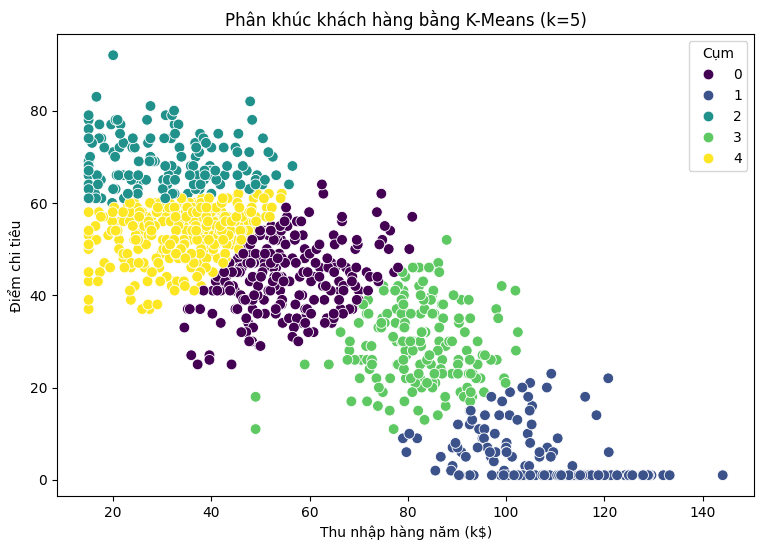

In [13]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
data['Cluster'] = kmeans.fit_predict(X_scaled)

print("Số lượng khách hàng mỗi cụm:")
display(data['Cluster'].value_counts().sort_index().rename('Số khách hàng').to_frame())

print("Tỷ lệ khách hàng mỗi cụm (%):")
display((data['Cluster'].value_counts(normalize=True).sort_index() * 100).round(2).rename('Tỷ lệ (%)').to_frame())

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=data,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='viridis',
    s=60
)
plt.title('Phân khúc khách hàng bằng K-Means (k=5)')
plt.xlabel('Thu nhập hàng năm (k$)')
plt.ylabel('Điểm chi tiêu')
plt.legend(title='Cụm')
plt.show()


**Mô hình K-Means được chạy với k = 5 và mỗi khách hàng được gán một nhãn cụm. Nhãn cụm chỉ là mã định danh do thuật toán tạo ra; số thứ tự 0–4 không tự mang ý nghĩa tốt/xấu và có thể hoán đổi giữa các lần chạy hoặc bộ dữ liệu khác nhau**

### 5.4. Đánh giá mô hình và chân dung các cụm

In [14]:
final_silhouette = silhouette_score(X_scaled, data['Cluster'])
final_wcss = kmeans.inertia_

print(f"WCSS với k=5: {final_wcss:.3f}")
print(f"Silhouette Score với k=5: {final_silhouette:.3f}")

cluster_profile = data.groupby('Cluster').agg(
    So_khach_hang=('Cluster', 'size'),
    Thu_nhap_trung_binh=('Annual Income (k$)', 'mean'),
    Diem_chi_tieu_trung_binh=('Spending Score (1-100)', 'mean'),
    Tuoi_trung_binh=('Age', 'mean')
).round(2)

cluster_profile['Ty_le_khach_hang_%'] = (
    cluster_profile['So_khach_hang'] / len(data) * 100
).round(2)

display(cluster_profile)


WCSS với k=5: 238.908
Silhouette Score với k=5: 0.366


,So_khach_hang,Thu_nhap_trung_binh,Diem_chi_tieu_trung_binh,Tuoi_trung_binh,Ty_le_khach_hang_%
Cluster,,,,,
0,239,55.34,43.93,37.02,23.9
1,136,106.91,5.26,65.08,13.6
2,151,31.03,68.85,28.68,15.1
3,176,82.48,29.71,45.82,17.6
4,298,34.06,53.12,29.61,29.8


**Silhouette tổng thể và WCSS được dùng để tham khảo chất lượng phân cụm. Đánh giá mô hình cần kết hợp các chỉ số này với khả năng diễn giải và tính hữu ích của từng nhóm khách hàng; không nên chỉ dựa vào một chỉ số duy nhất**

### 5.5. Bảng kết quả để đối chiếu với báo cáo
Lưu ý: số cụm K-Means có thể mang nhãn khác nhau giữa các lần chạy/phần mềm; hãy dựa vào thu nhập và điểm chi tiêu trung bình để gắn tên mô tả trong báo cáo.

In [15]:
# Bảng trung bình của các biến theo cụm, phục vụ đối chiếu
display(data.groupby('Cluster')[[
    'Age', 'Annual Income (k$)', 'Spending Score (1-100)'
]].mean().round(2))

# Xuất dữ liệu có nhãn cụm nếu cần sử dụng trong báo cáo
data.to_csv('customer_segments_kmeans.csv', index=False)
print("Đã tạo file customer_segments_kmeans.csv")


,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,37.02,55.34,43.93
1,65.08,106.91,5.26
2,28.68,31.03,68.85
3,45.82,82.48,29.71
4,29.61,34.06,53.12


Đã tạo file customer_segments_kmeans.csv


**Bảng trung bình theo cụm giúp mô tả đặc trưng điển hình của từng nhóm. Dùng các giá trị thực tế trong bảng để gán chân dung và đề xuất marketing tương ứng. Lưu ý nhãn cụm có thể khác thứ tự trong báo cáo; hãy đối chiếu theo đặc điểm thu nhập và điểm chi tiêu, không chỉ theo số hiệu cụm**

#**6. Kết luận chung**
Kết luận: Phân cụm khách hàng giúp nhận diện các nhóm có hành vi chi tiêu khác nhau, từ đó hỗ trợ xây dựng chiến lược marketing phù hợp cho từng nhóm. Khi hoàn thiện báo cáo, cần căn cứ vào số liệu và biểu đồ thực tế sau khi chạy notebook. Kết quả có thể khác báo cáo nếu tệp CSV, cách tiền xử lý hoặc đặc trưng đưa vào K-Means không giống nhau.

Hạn chế: K-Means nhạy với việc chọn số cụm, đặc trưng và cách chuẩn hóa; nhãn cụm không cố định về thứ tự. Các đề xuất marketing là gợi ý dựa trên đặc điểm cụm, cần được kiểm chứng thêm bằng dữ liệu bán hàng hoặc thử nghiệm thực tế.
